In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import seaborn as sns

# Configurar estilo dos gráficos
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

In [3]:
# Carregar dados
df = pd.read_csv('data/online_retail.csv', encoding='latin-1')

# Ver primeiras linhas
print("Primeiras linhas:")
print(df.head())

# Ver informações
print("\nInformações do dataset:")
print(df.info())

# Ver estatísticas
print("\nEstatísticas descritivas:")
print(df.describe())

# Ver colunas
print("\nColunas disponíveis:")
print(df.columns.tolist())

Primeiras linhas:
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

           InvoiceDate  UnitPrice  CustomerID         Country  
0  2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1  2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2  2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3  2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4  2010-12-01 08:26:00       3.39     17850.0  United Kingdom  

Informações do dataset:
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype 

In [4]:
#Verificar valores ausentes
print("Valores ausentes:")
print(df.isnull().sum())

# Remover linhas com valores ausentes críticos
df = df.dropna(subset=['CustomerID', 'InvoiceDate', 'Quantity', 'UnitPrice'])

#Remover Transações com quantidade ou preço negativo
df = df[df['Quantity'] > 0 ]
df = df[df['UnitPrice'] > 0]

#Criar coluna de valor total
df['TotalAmount'] = df['Quantity'] * df['UnitPrice']

#Converter data para datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

print(f"Dataset após limpeza: {len(df)} linhas")




Valores ausentes:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
Dataset após limpeza: 397884 linhas


In [5]:
#Data de referência (última data do dataset)
reference_date = df['InvoiceDate'].max() + pd.Timedelta(days=1)

#Calcular RFM por cliente
rfm = df.groupby('CustomerID').agg({
    'InvoiceDate' : lambda x: (reference_date - x.max()).days, #Recency
    'InvoiceNo' : 'count', #Frequency
    'TotalAmount' : 'sum' #Monetary
}).rename(columns={
    'InvoiceDate' : 'Recency',
    'InvoiceNo' : 'Frequency',
    'TotalAmount' : 'Monetary'
})

#Remover clientes com valores negativos ou zero
rfm = rfm[rfm['Monetary'] > 0]

print("Métricas RFM calculadas:")
print(rfm.head(10))

print("\nEstatísticas RFM:")
print(rfm.describe())

Métricas RFM calculadas:
            Recency  Frequency  Monetary
CustomerID                              
12346.0         326          1  77183.60
12347.0           2        182   4310.00
12348.0          75         31   1797.24
12349.0          19         73   1757.55
12350.0         310         17    334.40
12352.0          36         85   2506.04
12353.0         204          4     89.00
12354.0         232         58   1079.40
12355.0         214         13    459.40
12356.0          23         59   2811.43

Estatísticas RFM:
           Recency    Frequency       Monetary
count  4338.000000  4338.000000    4338.000000
mean     92.536422    91.720609    2054.266460
std     100.014169   228.785094    8989.230441
min       1.000000     1.000000       3.750000
25%      18.000000    17.000000     307.415000
50%      51.000000    41.000000     674.485000
75%     142.000000   100.000000    1661.740000
max     374.000000  7847.000000  280206.020000


In [6]:
#Normalizar RFM com StandardScaler
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm)

#Converter para Dataframe 
rfm_scaled_df = pd.DataFrame(
    rfm_scaled,
    columns= ['Recency', 'Frequency', 'Monetary'],
    index=rfm.index
)

print("Dados normalizados (primeiras linhas):")
print(rfm_scaled_df.head())

print("\nEstatísticas dos dados normalizados")
print(rfm_scaled_df.describe())

Dados normalizados (primeiras linhas):
             Recency  Frequency  Monetary
CustomerID                               
12346.0     2.334574  -0.396578  8.358668
12347.0    -0.905340   0.394649  0.250966
12348.0    -0.175360  -0.265435 -0.028596
12349.0    -0.735345  -0.081836 -0.033012
12350.0     2.174578  -0.326635 -0.191347

Estatísticas dos dados normalizados
            Recency     Frequency      Monetary
count  4.338000e+03  4.338000e+03  4.338000e+03
mean   2.702618e-17  1.801745e-17  1.801745e-17
std    1.000115e+00  1.000115e+00  1.000115e+00
min   -9.153401e-01 -3.965777e-01 -2.281344e-01
25%   -7.453445e-01 -3.266350e-01 -1.943495e-01
50%   -4.153533e-01 -2.217210e-01 -1.535104e-01
75%    4.946227e-01  3.619268e-02 -4.367134e-02
max    2.814561e+00  3.390157e+01  3.094634e+01


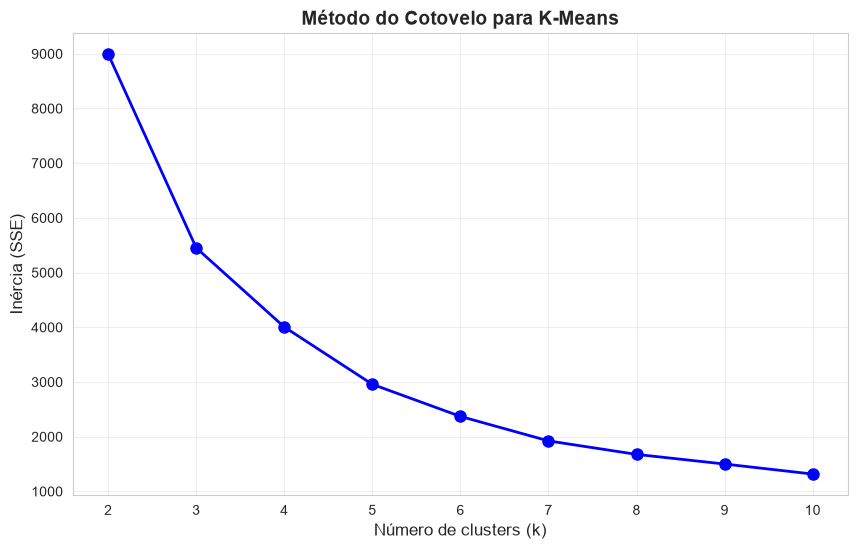

Gráfico salvo como: elbow_curve.png


In [7]:
#Testar diferentes valores de k
inertias = []
silhouette_scores = []
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(rfm_scaled)
    inertias.append(kmeans.inertia_)

#Plotar curva do cotovelo
plt.figure(figsize=(10,6))
plt.plot(K_range, inertias, 'bo-', linewidth=2, markersize=8)
plt.xlabel('Número de clusters (k)', fontsize=12)
plt.ylabel('Inércia (SSE)', fontsize=12)
plt.title('Método do Cotovelo para K-Means', fontsize=14,fontweight='bold')
plt.grid(True, alpha=0.3)
plt.xticks(K_range)
plt.savefig('elbow_curve.png', dpi=300, bbox_inches='tight')
plt.show()

print("Gráfico salvo como: elbow_curve.png")

In [8]:
# Aplicar K-Means com k=4 (geralmente é o ponto de cotovelo)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

print("Distribuição de clusters:")
print(rfm['Cluster'].value_counts().sort_index())

print("\nCentroides (valores originais):")
centroides = scaler.inverse_transform(kmeans.cluster_centers_)
centroides_df = pd.DataFrame(
    centroides,
    columns=['Recency', 'Frequency', 'Monetary']
)
print(centroides_df)

Distribuição de clusters:
Cluster
0    3248
1       4
2    1080
3       6
Name: count, dtype: int64

Centroides (valores originais):
      Recency    Frequency       Monetary
0   41.405846   104.578154    2091.172130
1    2.000000  5807.000000   70925.287500
2  247.495362    27.658627     636.564528
3    7.666667   826.833333  190863.461667


In [9]:
# Mapeamento CORRETO baseado nos dados reais
cluster_names = {
    0: 'Loyal',           # Recency=41, Frequency=105, Monetary=2091
    1: 'Champions',       # Recency=2, Frequency=5807, Monetary=70925
    2: 'At Risk',         # Recency=247, Frequency=28, Monetary=637
    3: 'VIP Customers'    # Recency=8, Frequency=827, Monetary=190863
}

rfm['Segment'] = rfm['Cluster'].map(cluster_names)

# Verificar resultado
print("Segmentação CORRIGIDA:")
print(rfm.groupby('Segment').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean',
    'Cluster': 'count'
}).rename(columns={'Cluster': 'Count'}).round(2))

# Salvar dados corrigidos
rfm.to_csv('data/customers_segmented.csv')
print("\nDados corrigidos salvos!")

Segmentação CORRIGIDA:
               Recency  Frequency   Monetary  Count
Segment                                            
At Risk         247.31      27.79     637.32   1080
Champions         2.00    5807.00   70925.29      4
Loyal            41.34     104.58    2091.82   3248
VIP Customers     7.67     826.83  190863.46      6

Dados corrigidos salvos!


In [10]:
#Atribuir nomes aos clusters (ajuste conforme análise acima)
rfm['Segment'] = rfm['Cluster'].map(cluster_names)

#Tamanho de cada segmento
segment_size = rfm['Segment'].value_counts()
print("Tamanho de cada segmento:")
print(segment_size)

#Valor total por segmento
segment_value = rfm.groupby('Segment')['Monetary'].sum().sort_values(ascending=False)
print("\nPercentual de receita por segmento:")
print(segment_value)

#Percentual de receita por segmento
segment_pct = (segment_value / segment_value.sum() * 100).round(2)
print("\nPercentual de receita por segmento:")
print(segment_pct)

#Salvar dados com segmentos
rfm.to_csv('data/customers_segmented.csv')
print("\nDados segmentados salvos em: data/customers_segmented.csv")


Tamanho de cada segmento:
Segment
Loyal            3248
At Risk          1080
VIP Customers       6
Champions           4
Name: count, dtype: int64

Percentual de receita por segmento:
Segment
Loyal            6794221.993
VIP Customers    1145180.770
At Risk           688303.991
Champions         283701.150
Name: Monetary, dtype: float64

Percentual de receita por segmento:
Segment
Loyal            76.24
VIP Customers    12.85
At Risk           7.72
Champions         3.18
Name: Monetary, dtype: float64

Dados segmentados salvos em: data/customers_segmented.csv


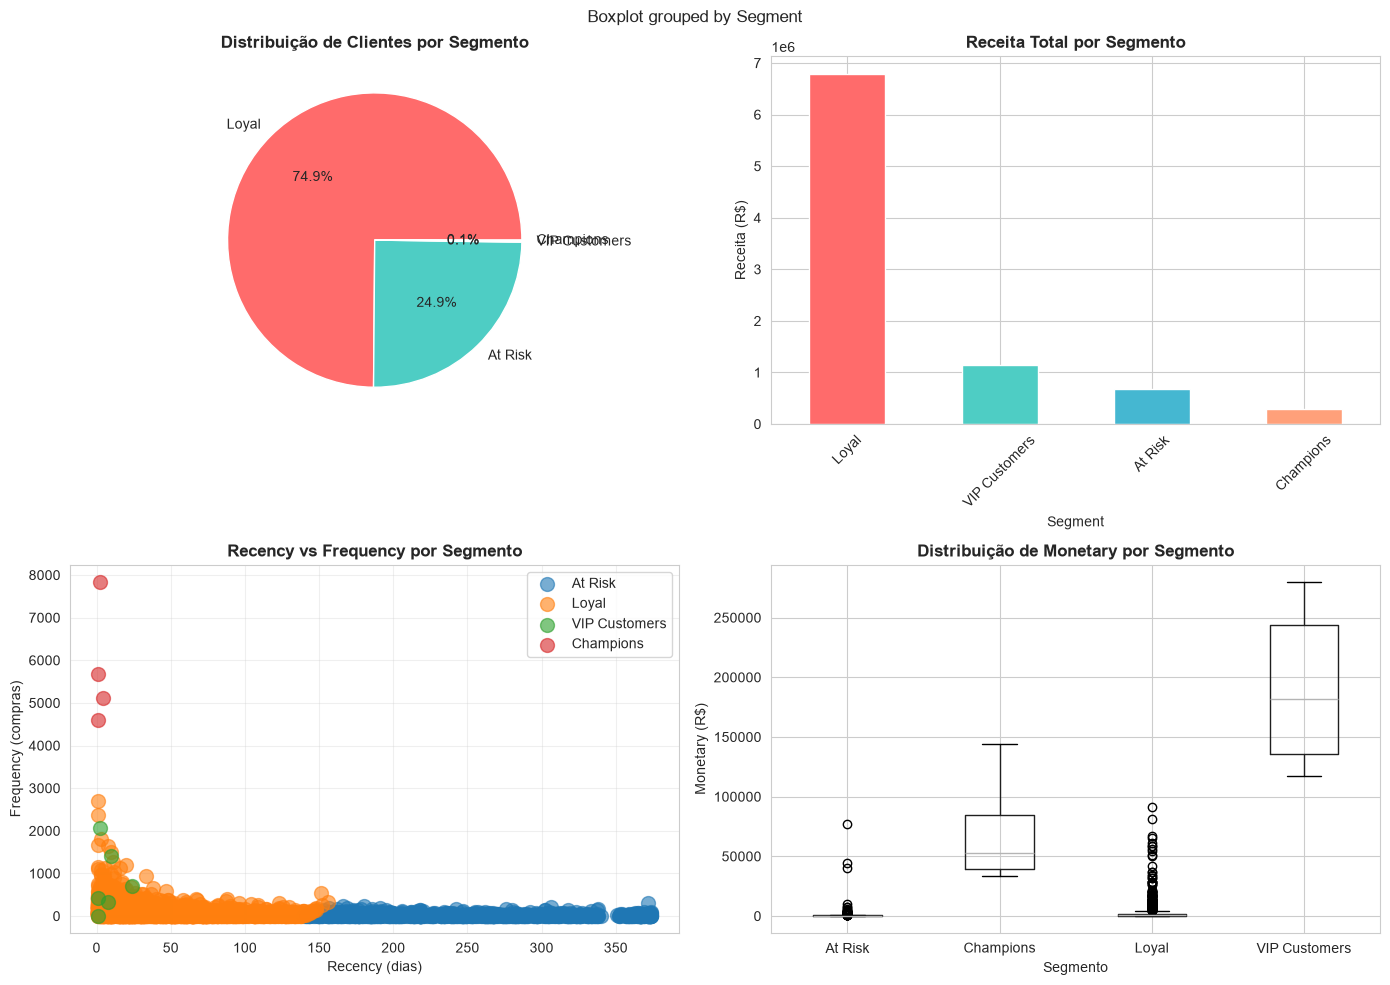

Gráficos salvos como: rfm_analysis.png


In [11]:
# Gráfico 1: Distribuição de segmentos
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Pie chart de distribuição
segment_size.plot(kind='pie', ax=axes[0, 0], autopct='%1.1f%%', colors=['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A'])
axes[0, 0].set_title('Distribuição de Clientes por Segmento', fontweight='bold')
axes[0, 0].set_ylabel('')

# Bar chart de receita
segment_value.plot(kind='bar', ax=axes[0, 1], color=['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A'])
axes[0, 1].set_title('Receita Total por Segmento', fontweight='bold')
axes[0, 1].set_ylabel('Receita (R$)')
axes[0, 1].tick_params(axis='x', rotation=45)

# Scatter: Recency vs Frequency
for segment in rfm['Segment'].unique():
    segment_data = rfm[rfm['Segment'] == segment]
    axes[1, 0].scatter(segment_data['Recency'], segment_data['Frequency'], 
                       label=segment, alpha=0.6, s=100)
axes[1, 0].set_xlabel('Recency (dias)')
axes[1, 0].set_ylabel('Frequency (compras)')
axes[1, 0].set_title('Recency vs Frequency por Segmento', fontweight='bold')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Box plot de Monetary
rfm.boxplot(column='Monetary', by='Segment', ax=axes[1, 1])
axes[1, 1].set_title('Distribuição de Monetary por Segmento', fontweight='bold')
axes[1, 1].set_xlabel('Segmento')
axes[1, 1].set_ylabel('Monetary (R$)')

plt.tight_layout()
plt.savefig('rfm_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

print("Gráficos salvos como: rfm_analysis.png")